# 05. Variance explained and phenotype prediction

Compare genetic relationship matrices built from six genomic contexts with background variants and size-matched control sets. Examine the variance explained in four environmental variables and the association between growing-season-length genetic scores and grain yield response to drought.

# 05. 方差解释与表型预测

比较六类基因组特征、背景变异及等量匹配对照构建的遗传关系矩阵。考察四个环境变量的方差解释，以及生长季长度遗传评分与干旱下籽粒产量响应的关联。

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
import json
import yaml
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
partition_dir = f'{results_dir}/partition'

from src.plot import set_plot_style
from src.partition import (
    run_partition_contrast, prepare_partition_summaries, plot_partition_summary,
)
set_plot_style()
print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')


Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python


## 1. Matched variant sets and genetic models

Use SNPs and indels passing the landrace quality filters (MAF ≥0.05, heterozygosity ≤0.05). Genic regions include gene bodies and ±2 kb flanks. Compare Genic regions, ACRs, and UMRs against Genome, and proximal ACRs, UMRs, and TEs against Proximal. Each background reference contains all variants in that background, including the foreground.

For each context, draw 1,000 control sets of equal size from non-foreground variants within its background, matching MAF, recombination, and nucleotide-diversity classes. When a matching stratum is too small, fill the remaining positions from unused background variants; record these substitutions. Fit each relationship matrix independently with LDAK REML, without population-PC covariates, and obtain BLUP genetic scores. The variance estimates are separate single-matrix fits and should not be summed across contexts.

## 1. 匹配变异集合与遗传模型

使用通过地方品种质控的SNP和indel（MAF ≥0.05、杂合率 ≤0.05）。Genic区域包含基因本体及±2 kb侧翼。Genic区域、ACRs和UMRs以Genome为背景；proximal ACRs、UMRs和TEs以Proximal为背景。背景参考包含该背景的所有变异，包括前景。

每类特征从背景中的非前景位点抽取1,000组等量对照，匹配MAF、重组率和核苷酸多样性类别。匹配分层位点不足时，从尚未使用的背景位点补足，并记录补充数量。分别使用LDAK REML拟合各遗传关系矩阵，不加入群体PC协变量，再获得BLUP遗传评分。这些方差估计来自独立的单矩阵模型，不能跨特征相加。

### 1.1 Samples and contexts

Train environmental models using the 443 landraces with available values for each environmental variable. The full imputed VCF provides both training and prediction genotypes; genomic context annotations define the retained variants.

### 1.1 样本与基因组特征

使用443个地方品种中具有对应环境观测值的样本训练模型。完整插补VCF同时提供训练和预测基因型，由基因组特征注释确定保留的变异。

In [2]:
vcf_file = f'{results_dir}/Sorghum_d8.allChr.imputed_snpeff.vcf.gz'
landrace_csv = f'{source_dir}/landraces_metadata.csv'
phenotype_csv = f'{source_dir}/Bernardino_2024_GxE_phenotypes.csv'
context_h5 = f'{results_dir}/site_contexts.genome.maf0.05.h5'
contrast_file = f'{project_dir}/config/contrasts_settings.json'
env_metadata_csv = f'{source_dir}/envir_metadata.csv'
env_id_list = ['bio18', 'gsl', 'al', 'striga']

contrast_ids = [
    'genic_2kb_vs_genome',
    'ACR_vs_genome',
    'UMR_vs_genome',
    'proximal_ACR_vs_proximal',
    'proximal_UMR_vs_proximal',
    'proximal_TE_vs_proximal',
]

feature_labels = {
    'genic_2kb_vs_genome': 'Genic ±2 kb vs. Genome',
    'ACR_vs_genome': 'ACRs vs. Genome',
    'UMR_vs_genome': 'UMRs vs. Genome',
    'proximal_ACR_vs_proximal': 'Proximal ACRs vs. Proximal',
    'proximal_UMR_vs_proximal': 'Proximal UMRs vs. Proximal',
    'proximal_TE_vs_proximal': 'Proximal TEs vs. Proximal',
}
contrast_dirs = {contrast_id: f'{partition_dir}/{contrast_id}' for contrast_id in contrast_ids}
with open(contrast_file) as handle:
    contrasts_settings = json.load(handle)

landraces_df = pd.read_csv(landrace_csv, dtype={'LIB': str})
phenotypes_df = pd.read_csv(phenotype_csv, dtype={'LIB': str})
for name, table in [('training', landraces_df), ('prediction', phenotypes_df)]:
    if table['LIB'].isna().any() or table['LIB'].duplicated().any():
        raise ValueError(f'{name}: LIB must be nonmissing and unique.')
predict_sample_ids = phenotypes_df['LIB'].tolist()
site_context_df = pd.read_hdf(context_h5, key='df')
site_context_df['genome'] = True

env_metadata_df = pd.read_csv(env_metadata_csv).set_index('env_id')
if env_metadata_df.index.duplicated().any():
    raise ValueError('Environment IDs must be unique.')
env_labels = {env_id: env_metadata_df.loc[env_id, 'description'] for env_id in env_id_list}
env_labels['striga'] = env_labels['striga'].replace('Striga', r'$\it{Striga}$')
pd.DataFrame({
    'ENV_ID': env_id_list,
    'N_TRAINING': [landraces_df[env_id].notna().sum() for env_id in env_id_list],
    'N_PREDICTION_GENOTYPES': len(predict_sample_ids),
})


,ENV_ID,N_TRAINING,N_PREDICTION_GENOTYPES
0,bio18,443,176
1,gsl,442,176
2,al,437,176
3,striga,440,176


### 1.2 Relationship matrices, REML, and BLUP scores

### 1.2 遗传关系矩阵、REML与BLUP评分

In [3]:
match_controls = ('MAF', 'Recomb', 'Pi')
n_perm = 1000
seed = 42
n_jobs = 80
threads_per_process = 1
overwrite = False
cleanup_grms = True
cleanup_variant_sets = True

for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = str(threads_per_process)
for executable in ['plink', 'ldak']:
    if shutil.which(executable) is None:
        raise FileNotFoundError(f'{executable} is required in the kernel environment.')


In [4]:
partition_runs = []
for contrast_id in tqdm(contrast_ids, desc='Genetic models', unit='contrast'):
    model_result = run_partition_contrast(
        contrast_id, contrasts_settings[contrast_id], site_context_df,
        landraces_df, env_id_list, predict_sample_ids, vcf_file, contrast_dirs[contrast_id],
        match_controls=match_controls, n_perm=n_perm, seed=seed,
        match_n_jobs=n_jobs, grm_n_jobs=n_jobs, reml_n_jobs=n_jobs,
        blup_n_jobs=n_jobs, score_n_jobs=n_jobs,
        pruned_vcf_file=None, overwrite=overwrite,
        cleanup_grms=cleanup_grms, cleanup_variant_sets=cleanup_variant_sets,
        use_complement=False, sample_from_all_sites=False,
    )
    final_dir = f'{contrast_dirs[contrast_id]}/final'
    for filename in ['reml_summary_unadjusted.csv', 'score_summary.csv', 'matching_metadata.json']:
        if not os.path.isfile(f'{final_dir}/{filename}'):
            raise FileNotFoundError(f'{final_dir}/{filename}')
    with open(f'{final_dir}/matching_metadata.json') as handle:
        matching = json.load(handle)
    partition_runs.append({
        'CONTRAST': contrast_id, 'FINAL_DIR': final_dir,
        'N_FALLBACK_MAX': max(matching.get('fallback_counts', [0])),
    })
    del model_result
pd.DataFrame(partition_runs)


Genetic models:  17%|█▋        | 1/6 [00:00<00:02,  1.93contrast/s]


[genic_2kb_vs_genome] Final outputs already exist, skipping contrast.


Genetic models:  33%|███▎      | 2/6 [00:01<00:02,  1.94contrast/s]


[ACR_vs_genome] Final outputs already exist, skipping contrast.


Genetic models:  50%|█████     | 3/6 [00:01<00:01,  1.96contrast/s]

...

Genetic models:  83%|████████▎ | 5/6 [00:02<00:00,  1.98contrast/s]


[proximal_UMR_vs_proximal] Final outputs already exist, skipping contrast.


Genetic models: 100%|██████████| 6/6 [00:03<00:00,  1.97contrast/s]


[proximal_TE_vs_proximal] Final outputs already exist, skipping contrast.


,CONTRAST,FINAL_DIR,N_FALLBACK_MAX
0,genic_2kb_vs_genome,/lustre/home/dobby/Work/Project/functional-gen...,610808
1,ACR_vs_genome,/lustre/home/dobby/Work/Project/functional-gen...,0
2,UMR_vs_genome,/lustre/home/dobby/Work/Project/functional-gen...,112
3,proximal_ACR_vs_proximal,/lustre/home/dobby/Work/Project/functional-gen...,0
4,proximal_UMR_vs_proximal,/lustre/home/dobby/Work/Project/functional-gen...,157
5,proximal_TE_vs_proximal,/lustre/home/dobby/Work/Project/functional-gen...,34752


## 2. Variance explained

Display the REML variance fraction for each context and environmental variable. Blue lines indicate context variants, gray lines indicate the corresponding complete background, and matched-control distributions are shown in olive. Stars denote two-sided empirical P <0.05 relative to the 1,000 control sets.

## 2. 方差解释

展示各类特征对环境变量的REML方差解释比例。蓝线表示特征位点，灰线表示对应的完整背景，橄榄色分布表示匹配对照。星号表示相对于1,000组对照的双侧经验P <0.05。

In [5]:
prediction_env = 'gsl'
target_phenotype = 'Grain_yield_plast'
summary_prefix = f'{partition_dir}/partition_summary.unadjusted'
force_recompute = False

partition_summary = prepare_partition_summaries(
    contrast_dirs, env_id_list, phenotype_csv, landrace_csv, summary_prefix,
    prediction_env=prediction_env, target_phenotype=target_phenotype,
    n_perm=n_perm, force_recompute=force_recompute,
)
partition_summary['tests']


[23:48:36] Reusing partition summaries: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/partition_summary.unadjusted


,ANALYSIS,CONTRAST,ENV_ID,TARGET,OBSERVED,BACKGROUND,P_VALUE,DIRECTION,N_CONTROL,N_SAMPLES,N_TRAINING_OVERLAP
0,variance,genic_2kb_vs_genome,bio18,bio18,0.612462,0.549066,0.001998,right,1000,NaN,NaN
1,variance,genic_2kb_vs_genome,gsl,gsl,0.833692,0.816914,0.001998,right,1000,NaN,NaN
2,variance,genic_2kb_vs_genome,al,al,0.801775,0.746488,0.001998,right,1000,NaN,NaN
3,variance,genic_2kb_vs_genome,striga,striga,0.684527,0.665571,0.001998,right,1000,NaN,NaN
4,prediction,genic_2kb_vs_genome,gsl,Grain_yield_plast,0.279233,0.279684,0.001998,right,1000,175.0,2.0
5,variance,ACR_vs_genome,bio18,bio18,0.614586,0.549066,0.565435,right,1000,NaN,NaN
6,variance,ACR_vs_genome,gsl,gsl,0.819648,0.816914,0.085914,left,1000,NaN,NaN
7,variance,ACR_vs_genome,al,al,0.805943,0.746488,0.051948,right,1000,NaN,NaN
8,variance,ACR_vs_genome,striga,striga,0.694216,0.665571,0.001998,right,1000,NaN,NaN
9,prediction,ACR_vs_genome,gsl,Grain_yield_plast,0.290235,0.279684,0.007992,right,1000,175.0,2.0


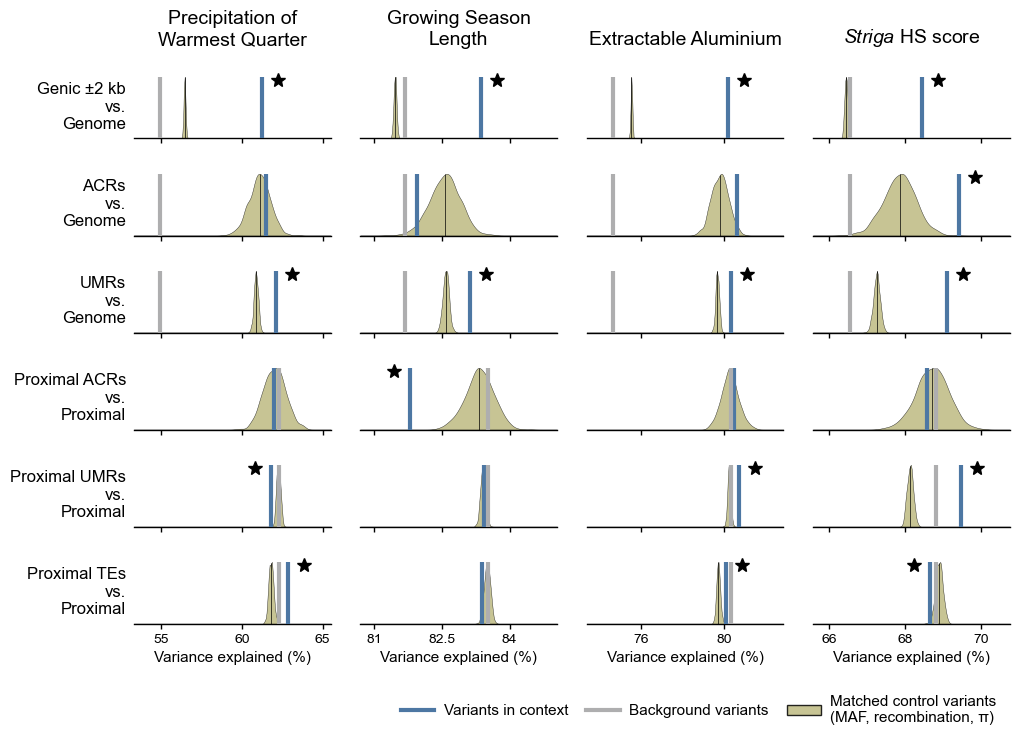

In [6]:
variance_feature_labels = {
    contrast_id: label.replace(' vs. ', '\nvs.\n')
    for contrast_id, label in feature_labels.items()
}
variance_env_labels = {
    **env_labels,
    'bio18': 'Precipitation of\nWarmest Quarter',
    'gsl': 'Growing Season\nLength',
    'al': 'Extractable Aluminium',
    'striga': r'$\it{Striga}$ HS score',
}
variance_plot_params = dict(
    figsize_per_col=3.0, figsize_per_row=1.,
    row_label_fontsize=12, column_title_fontsize=14,
    column_title_fontweight=None, tick_labelsize=10, label_wrap=None,
    left=0.25, top=0.88, hspace=0.08, line_lw=3.0,
    genome_legend_label='Background variants',
    control_legend_label='Matched control variants\n(MAF, recombination, π)',
    legend_fontsize=11, legend_x=0.98, legend_y=-0.04,
    legend_loc='lower right', legend_columnspacing=1.2,
    legend_handlelength=2.2, legend_handletextpad=0.6,
)
variance_plot = plot_partition_summary(
    summary_prefix, f'{partition_dir}/variance_explained', 'variance',
    variance_feature_labels, env_labels=variance_env_labels, **variance_plot_params,
)
plt.show()


## 3. Prediction performance

Assess Pearson's r between growing-season-length BLUP genetic scores and grain yield response to drought in the Bernardino G×E panel. Retain ISGR and IXRB, which also belong to the training panel: this evaluation therefore includes two training samples and is not completely independent. Only samples with finite target phenotypes enter the shared evaluation cohort.

For each context, compare the correlation with its complete background and matched controls. The right-hand panel shows the context genetic score, standardized to unit variance, against the original grain yield response. Stars denote two-sided empirical P <0.05 against the control correlations.

## 3. 预测表现

在Bernardino G×E样本中，计算生长季长度BLUP遗传评分与干旱下籽粒产量响应之间的Pearson相关系数。保留同样属于训练集的ISGR和IXRB，因此评估包含两个训练样本，并非完全独立。所有模型使用同一组具有有限目标表型值的评估样本。

各类特征的相关系数与其完整背景及匹配对照比较。右侧展示标准化至单位方差的特征遗传评分与原始籽粒产量响应。星号表示相对于对照相关系数的双侧经验P <0.05。

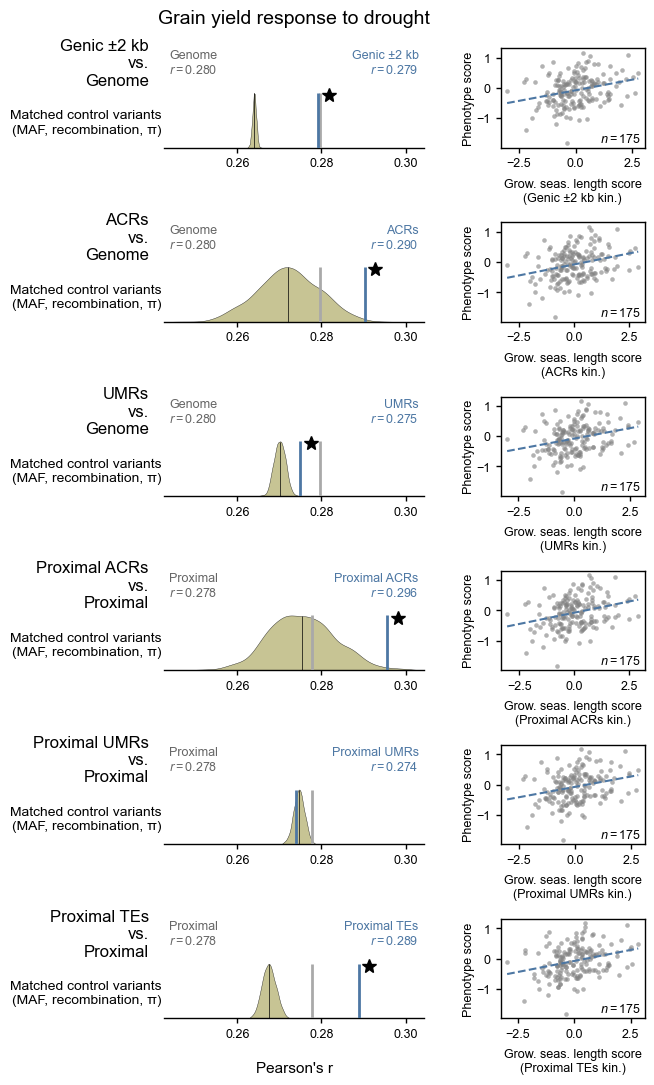

In [7]:
prediction_feature_labels = {
    contrast_id: label.split(' vs. ', 1)[0]
    for contrast_id, label in feature_labels.items()
}
prediction_row_labels = {
    contrast_id: label.replace(' vs. ', '\nvs.\n')
    for contrast_id, label in feature_labels.items()
}
prediction_plot_params = dict(
    figsize_per_col=6.2, figsize_per_row=2.1, width_ratios_pair=(1.8, 1.0),
    row_label_fontsize=12, title_fontsize=14, stat_fontsize=9,
    axis_label_fontsize=9, hist_axis_label_fontsize=11,
    tick_labelsize=9, group_label_fontsize=10,
    row_label_x=-0.06, row_label_y=0.85, row_label_ha='right',
    row_labels=prediction_row_labels, hspace=0.75, wspace=0.38,
    scatter_xlabel_y=-0.30, scatter_ylabel_x=-0.18,
    hist_xtick_step=0.02, phenotype_axis_label='Phenotype score',
    foreground_lw=2, genome_lw=2, scatter_s=11, scatter_alpha=0.6,
    r_label_position='corners', genome_label_y=0.85,
    hist_y_pad=0.18, genome_label_color='#666666',
    star_y_factor=0.96, star_offset_frac=0.04,
)
prediction_plot = plot_partition_summary(
    summary_prefix, f'{partition_dir}/prediction_performance', 'prediction',
    prediction_feature_labels, env_labels={'gsl': 'Grow. seas. length'},
    **prediction_plot_params,
)
plt.show()
